# 02 · Prediction models and Bayesian tuning

This notebook answers the validation half of RQ1 and the first optimization question of the course (Unit V):

1. the evaluation metric (T2.1)
2. baselines with default settings: EA potential, logistic regression, random forest, LightGBM (T2.2 to T2.5)
3. tuning LightGBM: Bayesian optimization (Optuna TPE) against random search, 50 trials × 5 seeds each (T2.6, T2.7)
4. tuning logistic regression, the random forest and the MLP with TPE (T3.1, T3.2)
5. the RQ1 validation table (T2.8)
6. the LightGBM model inside the fitness function: correctness and timing (T3.3, T3.4)

The 13 tuning studies take about an hour, so they run from the terminal (`python scripts/run_hpo.py all`) and write one CSV per study to `results/hpo/`. This notebook reads those files and refits each best configuration.
**Every score here is on the validation set (FIFA 19 to 20). The test set is not touched.**

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

from src import config, data, metrics, models, tuning
from src.features import D
from src.plotting import BLUE, GRAY, INK_SECONDARY, MUTED, plt, save, set_style

set_style()
config.ensure_dirs()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
TABLES = config.RESULTS / "tables"

df = data.load_main()
X_train, y_train = data.get_xy(df, "train")
X_val, y_val = data.get_xy(df, "val")
potential_val = df.loc[df["set"] == "val", "potential"].to_numpy()
print(f"train {X_train.shape}, {y_train.sum()} positives | validation {X_val.shape}, {y_val.sum()} positives")


def scores_row(name, y_true, scores):
    """Validation metrics for one model: PR-AUC, ROC-AUC and the top-50 shortlist."""
    out = metrics.evaluate(y_true, scores)
    out["precision_at_50"], out["recall_at_50"] = metrics.precision_recall_at_k(y_true, scores, 50)
    return pd.Series(out, name=name)

train (12148, 45), 344 positives | validation (3974, 45), 113 positives


## 1. The metric (T2.1)

Future elite players are rare (2.8% of validation rows), so accuracy is useless: calling every player "not elite" is 97% accurate.
The primary metric is **PR-AUC** (average precision), which measures how well the real future stars are ranked above everyone else.
A random ranking scores about the positive rate. `src/metrics.py` holds the helper used everywhere; here it is checked on three dummy rankings.

In [2]:
rng = np.random.default_rng(0)
dummy = pd.DataFrame([
    scores_row("random scores", y_val, rng.random(len(y_val))),
    scores_row("perfect ranking", y_val, y_val + 0.0),
    scores_row("reversed ranking", y_val, -y_val + 0.0),
])
print(f"validation positive rate (the PR-AUC of a random ranking): {y_val.mean():.4f}")
dummy.round(4)

validation positive rate (the PR-AUC of a random ranking): 0.0284


,pr_auc,roc_auc,precision_at_50,recall_at_50
random scores,0.0299,0.5041,0.04,0.0177
perfect ranking,1.0000,1.0000,1.00,0.4425
reversed ranking,0.0284,0.0000,0.00,0.0000


## 2. Baselines with default settings (T2.2 to T2.5)

* **EA potential** is used directly as the score (H1b: the models must beat it).
* **Logistic regression**: median imputation, standardisation, L2 penalty with `C = 1`, class weights.
* **Random forest**: 500 trees, `max_features = "sqrt"`, class weights, median imputation.
* **LightGBM**: library defaults (100 trees, learning rate 0.1, 31 leaves) with `scale_pos_weight` = negatives / positives in train.

Every model is fitted on train only; imputation and scaling sit inside the pipeline, so they never see validation data.

In [3]:
print(f"scale_pos_weight = {models.class_ratio(y_train):.2f}")
rows, fitted = [scores_row("EA potential", y_val, potential_val)], {}
for name in ["logreg", "rf", "lgbm"]:
    start = time.perf_counter()
    fitted[name] = models.fit(name, {}, X_train, y_train)
    row = scores_row(models.MODEL_LABEL[name], y_val, models.scores(fitted[name], X_val))
    row["fit_seconds"] = time.perf_counter() - start
    rows.append(row)
defaults = pd.DataFrame(rows)
defaults.round(4)

scale_pos_weight = 34.31


,pr_auc,roc_auc,precision_at_50,recall_at_50,fit_seconds
EA potential,0.4232,0.9609,0.56,0.2478,NaN
Logistic regression,0.4834,0.9627,0.58,0.2566,2.4562
Random forest,0.5136,0.9579,0.66,0.2920,3.0063
LightGBM,0.5258,0.9507,0.66,0.2920,0.1841


EA's own potential rating is already a strong ranking (PR-AUC 0.42, ROC-AUC 0.96): it is built by EA's scouts with exactly this question in mind.
All three models beat it with default settings, LightGBM by the most (0.53).

## 3. Tuning LightGBM: Bayesian optimization against random search (T2.6, T2.7)

Search space (seven hyperparameters):

| Hyperparameter | Range |
| --- | --- |
| `num_leaves` | 15 to 255 |
| `learning_rate` | 0.01 to 0.2, log scale |
| `n_estimators` | 100 to 1000 |
| `min_child_samples` | 5 to 100 |
| `subsample` (with `subsample_freq = 1`) | 0.5 to 1 |
| `colsample_bytree` | 0.5 to 1 |
| `reg_lambda` | 0.001 to 10, log scale |

* **Bayesian optimization**: Optuna's Tree-structured Parzen Estimator (TPE). It models which regions gave good and bad trials so far and samples where the ratio is favourable.
* **Control**: Optuna's random sampler over the same space.
* 50 trials per study, sampler seeds 0 to 4. The model seed is fixed, so two studies differ only in the hyperparameters they proposed.

In [4]:
studies = {(s, k): pd.read_csv(config.HPO_DIR / f"lgbm_{s}_seed{k}.csv") for s in ("tpe", "random") for k in config.HPO_SEEDS}
assert all(len(t) == config.HPO_TRIALS for t in studies.values())
curves = {s: np.array([studies[(s, k)]["best_so_far"].to_numpy() for k in config.HPO_SEEDS]) for s in ("tpe", "random")}

per_seed = pd.DataFrame({
    "TPE best": [studies[("tpe", k)]["value"].max() for k in config.HPO_SEEDS],
    "random best": [studies[("random", k)]["value"].max() for k in config.HPO_SEEDS],
    "TPE trial of best": [int(studies[("tpe", k)]["value"].idxmax()) + 1 for k in config.HPO_SEEDS],
    "random trial of best": [int(studies[("random", k)]["value"].idxmax()) + 1 for k in config.HPO_SEEDS],
}, index=pd.Index(config.HPO_SEEDS, name="seed"))
per_seed["TPE ahead"] = per_seed["TPE best"] > per_seed["random best"]
per_seed.round(4)

,TPE best,random best,TPE trial of best,random trial of best,TPE ahead
seed,,,,,
0,0.5932,0.5922,36,22,True
1,0.5941,0.5953,33,23,False
2,0.5962,0.5879,34,5,True
3,0.5939,0.5858,21,33,True
4,0.6008,0.5972,31,9,True


In [5]:
def first_reaching(curve, threshold):
    hit = np.flatnonzero(curve >= threshold)
    return int(hit[0]) + 1 if hit.size else np.nan


summary = {}
for s, label in (("tpe", "TPE"), ("random", "Random search")):
    c = curves[s]
    after_startup = pd.concat([studies[(s, k)].iloc[10:] for k in config.HPO_SEEDS])["value"]
    summary[label] = {
        "best after 50 trials (mean)": c[:, -1].mean(),
        "best after 50 trials (sd)": c[:, -1].std(ddof=1),
        "best after 10 trials (mean)": c[:, 9].mean(),
        "best after 25 trials (mean)": c[:, 24].mean(),
        "mean of best-so-far curve": c.mean(),
        "trials 11-50 scoring >= 0.58 (share)": (after_startup >= 0.58).mean(),
        "trials 11-50: median PR-AUC": after_startup.median(),
        "seeds reaching 0.59": int(np.isfinite([first_reaching(r, 0.59) for r in c]).sum()),
        "trials to reach 0.59 (median, reached only)": np.nanmedian([first_reaching(r, 0.59) for r in c]),
    }
bo_summary = pd.DataFrame(summary)
bo_summary.round(4).to_csv(TABLES / "hpo_bo_vs_random.csv")
bo_summary.round(4)

,TPE,Random search
best after 50 trials (mean),0.5956,0.5917
best after 50 trials (sd),0.0031,0.0048
best after 10 trials (mean),0.5886,0.5886
best after 25 trials (mean),0.5926,0.5915
mean of best-so-far curve,0.5907,0.5890
trials 11-50 scoring >= 0.58 (share),0.4150,0.1000
trials 11-50: median PR-AUC,0.5785,0.5605
seeds reaching 0.59,5.0000,3.0000
"trials to reach 0.59 (median, reached only)",21.0000,17.0000


In [6]:
w_final = wilcoxon(curves["tpe"][:, -1], curves["random"][:, -1])
w_area = wilcoxon(curves["tpe"].mean(axis=1), curves["random"].mean(axis=1))
print(f"Wilcoxon signed-rank, paired by seed (n = 5): final best p = {w_final.pvalue:.4f}; curve mean p = {w_area.pvalue:.4f}")
print("With 5 pairs the smallest possible two-sided p-value is 2 / 2^5 = 0.0625, so 5 seeds cannot show significance at 0.05.")

Wilcoxon signed-rank, paired by seed (n = 5): final best p = 0.1875; curve mean p = 0.3125
With 5 pairs the smallest possible two-sided p-value is 2 / 2^5 = 0.0625, so 5 seeds cannot show significance at 0.05.


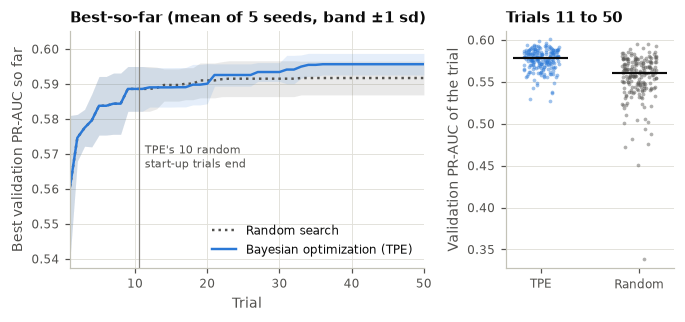

In [7]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(6.3, 3.0), gridspec_kw={"width_ratios": [2.1, 1]})
trials = np.arange(1, config.HPO_TRIALS + 1)
for s, label, color, ls in (("random", "Random search", GRAY, ":"), ("tpe", "Bayesian optimization (TPE)", BLUE, "-")):
    mean, sd = curves[s].mean(axis=0), curves[s].std(axis=0, ddof=1)
    ax.plot(trials, mean, color=color, linestyle=ls, label=label)
    ax.fill_between(trials, mean - sd, mean + sd, color=color, alpha=0.12, linewidth=0)
ax.axvline(10.5, color=MUTED, linewidth=0.8)
ax.annotate("TPE's 10 random\nstart-up trials end", (10.5, 0.565), xytext=(4, 0), textcoords="offset points",
            fontsize=7.5, color=INK_SECONDARY, va="bottom")
ax.set(xlabel="Trial", ylabel="Best validation PR-AUC so far", title="Best-so-far (mean of 5 seeds, band ±1 sd)",
       xlim=(1, 50), ylim=(min((curves[s].mean(axis=0) - curves[s].std(axis=0, ddof=1)).min() for s in curves) - 0.003, 0.605))
ax.legend(loc="lower right")

values = {s: pd.concat([studies[(s, k)].iloc[10:] for k in config.HPO_SEEDS])["value"].to_numpy() for s in ("tpe", "random")}
jitter = np.random.default_rng(1)
for i, (s, color) in enumerate((("tpe", BLUE), ("random", GRAY))):
    ax2.scatter(i + jitter.uniform(-0.18, 0.18, len(values[s])), values[s], s=6, color=color, alpha=0.45, linewidths=0)
    ax2.hlines(np.median(values[s]), i - 0.28, i + 0.28, color="#0b0b0b", linewidth=1.4)
ax2.set_xticks([0, 1], ["TPE", "Random"])
ax2.set(ylabel="Validation PR-AUC of the trial", title="Trials 11 to 50",
        ylim=(min(v.min() for v in values.values()) - 0.01, 0.61))
ax2.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "fig02a_bo_vs_random")
plt.show()

**What the comparison shows.**

* For the first 10 trials the two curves are the same, because TPE starts with 10 random start-up trials drawn from the same seeded generator as the random sampler.
* After that TPE concentrates its trials in good regions: 42% of its trials 11 to 50 score at least 0.58, against 10% for random search, and its median trial is better by 0.018 (0.579 against 0.561).
* The best configuration found improves less: 0.5956 for TPE against 0.5917 for random search after 50 trials (TPE ahead on 4 of 5 seeds). TPE reaches 0.59 on all 5 seeds, random search on 3.
* With 5 seeds the difference cannot be significant (Wilcoxon p = 0.19; the floor is 0.0625). The honest summary: **Bayesian optimization finds good settings more reliably, but in this small 7-dimensional space random search with 50 trials is a strong competitor**, as Bergstra and Bengio (2012) found for problems with few important hyperparameters.

## 4. Tuning logistic regression, the random forest and the MLP (T3.1, T3.2)

Each model gets one TPE study with 50 trials and seed 0, the same budget LightGBM's seed-0 study had, so the RQ1 comparison is fair.

| Model | Search space | Fixed |
| --- | --- | --- |
| Logistic regression | `C` 0.0001 to 100 (log) | L2, class weights |
| Random forest | `max_depth` 3 to 20, `min_samples_leaf` 1 to 50, `max_features` 0.1 to 1 | 500 trees, class weights |
| MLP (Keras, GPU) | hidden units 32 to 256, 2 or 3 layers, dropout 0 to 0.5, learning rate 0.0001 to 0.01 (log), weight decay 0.000001 to 0.001 (log) | ReLU, AdamW, batch 256, weighted BCE with `pos_weight` = 34.3, early stopping on validation PR-AUC (patience 10) |

The final LightGBM configuration is the best trial of the **seed-0 TPE study** (validation PR-AUC 0.5932), not the best of all ten studies (0.6008), so every model is tuned with exactly 50 trials. Picking the best of 500 trials would overfit the validation set.

In [8]:
from src import mlp as mlp_module

print("MLP trains on:", mlp_module.device_name())
best, tuned_rows, tuned_models = {}, [], {}
for name in ["logreg", "rf", "lgbm", "mlp"]:
    trials_df = pd.read_csv(config.HPO_DIR / f"{name}_tpe_seed0.csv")
    best[name] = tuning.best_params(trials_df)
    tuning.save_params(best[name], config.HPO_DIR / f"best_params_{name}.json")
    start = time.perf_counter()
    tuned_models[name] = models.fit(name, best[name], X_train, y_train, X_val, y_val)
    row = scores_row(models.MODEL_LABEL[name], y_val, models.scores(tuned_models[name], X_val))
    row["fit_seconds"] = time.perf_counter() - start
    row["study best"] = trials_df["value"].max()
    tuned_rows.append(row)
tuned = pd.DataFrame(tuned_rows)
tuned["refit matches study"] = (tuned["pr_auc"] - tuned["study best"]).abs() < 1e-9
tuned.round(4)

MLP trains on: NVIDIA GeForce RTX 3050 Laptop GPU


,pr_auc,roc_auc,precision_at_50,recall_at_50,fit_seconds,study best,refit matches study
Logistic regression,0.5316,0.9658,0.58,0.2566,0.5686,0.5316,True
Random forest,0.5388,0.9563,0.72,0.3186,2.8855,0.5388,True
LightGBM,0.5932,0.9516,0.82,0.3628,2.2475,0.5932,True
MLP,0.5728,0.9623,0.70,0.3097,12.7122,0.5728,True


In [9]:
pd.Series({m: best[m] for m in best}, name="best hyperparameters").to_frame()

,best hyperparameters
logreg,{'C': 0.003185857657837453}
rf,"{'max_depth': 17, 'min_samples_leaf': 10, 'max_features': 0.16027138005715547}"
lgbm,"{'num_leaves': 248, 'learning_rate': 0.09905604258159961, 'n_estimators': 962, 'min_child_samples': 67, 'subsample':..."
mlp,"{'hidden': 113, 'n_layers': 2, 'dropout': 0.4721427322395372, 'learning_rate': 0.0016708061134378038, 'weight_decay'..."


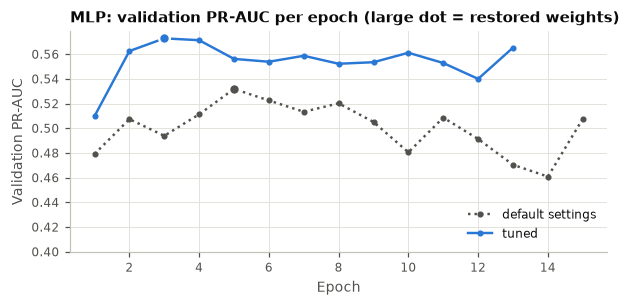

default MLP: best epoch 5 of 15 | tuned MLP: best epoch 3 of 13


In [10]:
mlp_default = models.fit("mlp", {}, X_train, y_train, X_val, y_val)
mlp_tuned = tuned_models["mlp"]
fig, ax = plt.subplots(figsize=(6.3, 2.6))
for model, label, color, ls in ((mlp_default, "default settings", GRAY, ":"),
                                (mlp_tuned, "tuned", BLUE, "-")):
    epochs = np.arange(1, len(model.val_curve_) + 1)
    ax.plot(epochs, model.val_curve_, color=color, linestyle=ls, marker="o", markersize=3, label=label)
    ax.plot(model.best_epoch_, model.best_val_pr_auc_, marker="o", markersize=7, color=color,
            markeredgecolor="white", markeredgewidth=1.5, linestyle="none")
ax.set(xlabel="Epoch", ylabel="Validation PR-AUC", title="MLP: validation PR-AUC per epoch (large dot = restored weights)",
       ylim=(0.40, None))
ax.legend(loc="lower right")
save(fig, "fig02b_mlp_training")
plt.show()
print(f"default MLP: best epoch {mlp_default.best_epoch_} of {len(mlp_default.val_curve_)} | "
      f"tuned MLP: best epoch {mlp_tuned.best_epoch_} of {len(mlp_tuned.val_curve_)}")

Both MLPs peak within the first few epochs and then decline: with this little signal (344 positives) and the shift between old and new game versions, the network starts fitting train-specific patterns almost at once.
Early stopping with restored weights is what keeps it competitive. The tuned network settles on strong dropout (0.47).

## 5. RQ1 validation table (T2.8)

In [11]:
table = []
for _, r in defaults.iterrows():
    table.append({"model": r.name, "setting": "baseline" if r.name == "EA potential" else "default",
                  "val PR-AUC": r["pr_auc"], "val ROC-AUC": r["roc_auc"],
                  "val precision@50": r["precision_at_50"], "val recall@50": r["recall_at_50"]})
mlp_row = scores_row("MLP", y_val, models.scores(mlp_default, X_val))
table.append({"model": "MLP", "setting": "default", "val PR-AUC": mlp_row["pr_auc"], "val ROC-AUC": mlp_row["roc_auc"],
              "val precision@50": mlp_row["precision_at_50"], "val recall@50": mlp_row["recall_at_50"]})
for _, r in tuned.iterrows():
    table.append({"model": r.name, "setting": "tuned (TPE, 50 trials)", "val PR-AUC": r["pr_auc"], "val ROC-AUC": r["roc_auc"],
                  "val precision@50": r["precision_at_50"], "val recall@50": r["recall_at_50"]})
rq1_val = pd.DataFrame(table)
rq1_val.round(4).to_csv(TABLES / "rq1_validation.csv", index=False)
rq1_val.round(4)

,model,setting,val PR-AUC,val ROC-AUC,val precision@50,val recall@50
0,EA potential,baseline,0.4232,0.9609,0.56,0.2478
1,Logistic regression,default,0.4834,0.9627,0.58,0.2566
2,Random forest,default,0.5136,0.9579,0.66,0.2920
3,LightGBM,default,0.5258,0.9507,0.66,0.2920
4,MLP,default,0.5318,0.9618,0.64,0.2832
5,Logistic regression,"tuned (TPE, 50 trials)",0.5316,0.9658,0.58,0.2566
6,Random forest,"tuned (TPE, 50 trials)",0.5388,0.9563,0.72,0.3186
7,LightGBM,"tuned (TPE, 50 trials)",0.5932,0.9516,0.82,0.3628
8,MLP,"tuned (TPE, 50 trials)",0.5728,0.9623,0.70,0.3097


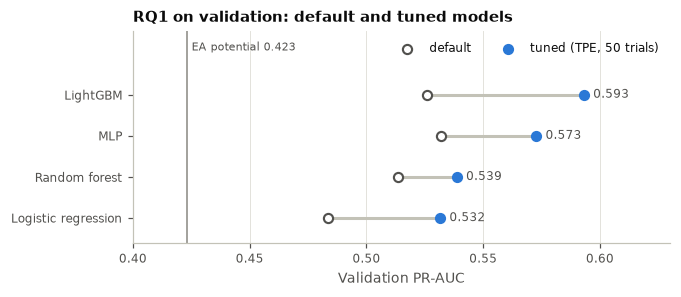

In [12]:
order = ["Logistic regression", "Random forest", "MLP", "LightGBM"]
fig, ax = plt.subplots(figsize=(6.3, 2.5))
pot = float(rq1_val.loc[rq1_val["model"] == "EA potential", "val PR-AUC"].iloc[0])
ax.axvline(pot, color=MUTED, linewidth=1)
ax.annotate(f"EA potential {pot:.3f}", (pot, len(order) + 0.15), xytext=(3, 0), textcoords="offset points",
            fontsize=7.5, color=INK_SECONDARY, va="center")
for i, m in enumerate(order):
    d = rq1_val.query("model == @m and setting == 'default'")["val PR-AUC"].iloc[0]
    t = rq1_val.query("model == @m and setting != 'default'")["val PR-AUC"].iloc[0]
    ax.plot([d, t], [i, i], color="#c3c2b7", linewidth=2, zorder=1)
    ax.scatter(d, i, s=36, facecolor="white", edgecolor=GRAY, linewidth=1.4, zorder=2, label="default" if i == 0 else None)
    ax.scatter(t, i, s=40, color=BLUE, zorder=3, label="tuned (TPE, 50 trials)" if i == 0 else None)
    ax.annotate(f"{t:.3f}", (t, i), xytext=(6, 0), textcoords="offset points", fontsize=8, color=INK_SECONDARY, va="center")
ax.set_yticks(range(len(order)), order)
ax.set(xlabel="Validation PR-AUC", title="RQ1 on validation: default and tuned models", xlim=(0.40, 0.63), ylim=(-0.6, len(order) + 0.55))
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", ncols=2)
save(fig, "fig02c_rq1_validation")
plt.show()

**Validation results for RQ1.**

* Every model beats EA's potential rating on validation PR-AUC, the tuned ones by 0.11 to 0.17. ROC-AUC barely separates them (0.95 to 0.97), which is why PR-AUC is the primary metric.
* Tuning helps every model; LightGBM gains the most (0.526 to 0.593).
* Order after tuning: LightGBM 0.593 > MLP 0.573 > random forest 0.539 > logistic regression 0.532. This is in line with H1a (trees match or beat the MLP), but the gap is small and the test set will decide.
* Shortlist view: 41 of tuned LightGBM's top 50 validation players become elite (precision 0.82), which is 36% of the 113 who do. A random shortlist of 50 would contain one or two.

## 6. The model inside the fitness function (T3.3, T3.4)

The optimizers call the fitness function thousands of times, so it uses LightGBM with **fixed, moderate settings** (200 trees, learning rate 0.05, `scale_pos_weight`, seed 0, 4 threads) instead of tuned ones:

$$f(\mathbf{x}) = 0.99\,\bigl(1 - \text{PR-AUC}_{\text{val}}(\mathbf{x})\bigr) + 0.01\,\frac{|\mathbf{x}|}{45}$$

`src/fitness.py` repairs an all-zero vector (one random feature switched on), caches validation PR-AUC by subset, and logs every call.
Every call counts toward an optimizer's budget of 600, cache hit or not, so each algorithm gets exactly 600 looks (decision D17).

In [13]:
from src.fitness import FitnessFunction

fitness = FitnessFunction(X_train, y_train, X_val, y_val)
all_features = np.ones(D, dtype=np.uint8)
only_overall = np.zeros(D, dtype=np.uint8)
only_overall[0] = 1
f_all = fitness(all_features)
print(f"all 45 features: fitness {f_all:.5f}, validation PR-AUC {fitness.log[-1]['pr_auc']:.4f}  (tuned LightGBM: {tuned.loc[tuned.index[2], 'pr_auc']:.4f})")
fitness(only_overall)
print(f"current overall alone: fitness {fitness.log[-1]['fitness']:.5f}, validation PR-AUC {fitness.log[-1]['pr_auc']:.4f}")

masks = np.random.default_rng(0).integers(0, 2, size=(20, D), dtype=np.uint8)
seconds = []
for mask in masks:
    start = time.perf_counter()
    fitness(mask)
    seconds.append(time.perf_counter() - start)
start = time.perf_counter()
again = fitness(masks[0])
hit_seconds = time.perf_counter() - start
fresh = FitnessFunction(X_train, y_train, X_val, y_val)(masks[0])
timing = pd.Series({
    "mean seconds per evaluation (20 random subsets)": np.mean(seconds),
    "slowest of the 20 (s)": np.max(seconds),
    "cache hit (microseconds)": hit_seconds * 1e6,
    "repeat call returns the same fitness": again == fitness.log[2]["fitness"],
    "a fresh fitness object reproduces it exactly": fresh == fitness.log[2]["fitness"],
    "random subsets: mean validation PR-AUC": np.mean([e["pr_auc"] for e in fitness.log[2:22]]),
}, name="value", dtype=object)
timing

all 45 features: fitness 0.50567, validation PR-AUC 0.4993  (tuned LightGBM: 0.5932)
current overall alone: fitness 0.52423, validation PR-AUC 0.4707


mean seconds per evaluation (20 random subsets)    0.225997
slowest of the 20 (s)                              0.263817
cache hit (microseconds)                             90.529
repeat call returns the same fitness                   True
a fresh fitness object reproduces it exactly           True
random subsets: mean validation PR-AUC             0.484257
Name: value, dtype: object

In [14]:
calls = len(config.RUN_SEEDS) * 4 * config.BUDGET
print(f"main experiment: 4 methods x 10 seeds x {config.BUDGET} calls = {calls:,} calls")
print(f"worst case without cache hits: {calls * np.mean(seconds) / 3600:.1f} hours of training, "
      f"about {calls * np.mean(seconds) / 3600 / 4:.1f} hours on 4 parallel workers")

main experiment: 4 methods x 10 seeds x 600 calls = 24,000 calls
worst case without cache hits: 1.5 hours of training, about 0.4 hours on 4 parallel workers


**Fitness function verdict.** One evaluation takes about a quarter of a second, far below the plan's 3-second fallback trigger, so the plan's budget (600 calls, population 20) stays and no fallback is needed.
Repeated subsets cost microseconds, and the value is exactly reproducible.

Two numbers here shape the rest of the study:

* With fixed settings, LightGBM on **all 45 features scores only 0.499**, below the tuned model (0.593) and below many random subsets (mean 0.48, up to 0.53). Some features evidently hurt more than they help when a model trained on FIFA 15 to 18 is applied to FIFA 19 to 20. Feature selection has room to improve accuracy, not only to shrink the checklist.
* Current overall alone already reaches 0.471. It carries most of the signal.